
### Abstract

Zachary's Karate Club network is the "hello world" of community detection: 34 members, 78 friendships, and a known outcome, because the club really did break into two. In this notebook we implement Newman's spectral modularity method from scratch, apply it recursively to find more than two communities, and then follow four node metrics (degree, betweenness, closeness and clustering) as the graph is cut into communities.

**In short:** the very first spectral split puts 33 of the 34 members on the side they really joined (Q = 0.3715). Three more splits give five communities with Q = 0.4094. When the network is cut, the nodes that lose the most importance are the bridges between the factions, while the two leaders and node 32 stay central on their own side.

### Contents

0. Setup
1. The Karate Club data
2. Modularity in brief
3. Building the modularity matrix
4. One spectral split
5. Recursive bisection
6. Visualising the communities
7. Node metrics after every split
8. Discussion
9. Conclusion and references

### Where each assignment task lives

| Task from the handout | Section |
|---|---|
| 1. Recursive spectral modularity partitioning | 5 |
| 2. Visualise the graph after each split, one colour per community | 6 |
| 3. Degree, betweenness, closeness and clustering after each split | 7 |
| 4. Plot the evolution of every metric for every node | 7 |
| 5. Short discussion | 8 |

*Requirements:* Python 3.9+, `numpy`, `networkx`, `matplotlib`, plus `pandas` and `scipy` for tables and plot shading. The partitioning itself only uses NumPy linear algebra; NetworkX supplies the graph and the four metric functions. Run the notebook top to bottom. Figures and a CSV with all node metrics are written to the `outputs/` folder.

## 0. Setup

Imports, a clean plot style and one colour per community (blue is Mr. Hi's side, red is the president's side).

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch, Polygon
from scipy.spatial import ConvexHull
from pathlib import Path
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
})

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

def finish(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")
    plt.show()

# one colour per community: blue = Mr. Hi's side, red = the president's side
PALETTE = ["#2563EB", "#DC2626", "#059669", "#D97706", "#DB2777", "#7C3AED", "#0D9488", "#475569"]

## 1. The Karate Club data

In the early 1970s the anthropologist Wayne Zachary spent two years watching a university karate club. He recorded which of the 34 members spent time together outside class: each member is a node and each regular pair of friends is an edge. While he was there, the instructor ("Mr. Hi", node 0) and the club administrator (the president, node 33) fell out over money, and the club split into two. The friendships were recorded *before* the split, so we can ask whether the graph alone is enough to predict it.

Two details of the data:

- Recent NetworkX versions ship the graph with edge weights. The handout works with the plain unweighted graph, so we turn the adjacency matrix into 0/1 entries and ask the layout to ignore weights. All four NetworkX metrics are unweighted by default.
- Each node carries a `club` attribute with the faction it really joined. We use it **only to judge** the result, never inside the algorithm.

In [2]:
G = nx.karate_club_graph()
n, m = G.number_of_nodes(), G.number_of_edges()

# recent networkx versions attach edge weights, we only want the plain 0/1 graph
A = (nx.to_numpy_array(G, nodelist=range(n)) > 0).astype(float)
k = A.sum(axis=1)

pos = nx.spring_layout(G, seed=42, k=0.38, weight=None)   # same layout in every plot

# real factions, only used to judge the result, never by the algorithm
truth = np.array([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in range(n)])

print(f"nodes: {n}   edges: {m}   density: {nx.density(G):.3f}   connected: {nx.is_connected(G)}")
print(f"degrees: min {int(k.min())}, max {int(k.max())}, mean {k.mean():.2f}   (node 0 has {int(k[0])}, node 33 has {int(k[33])})")
print(f"real split: {np.sum(truth == 0)} members followed Mr. Hi, {np.sum(truth == 1)} followed the president")

nodes: 34   edges: 78   density: 0.139   connected: True
degrees: min 1, max 17, mean 4.59   (node 0 has 16, node 33 has 17)
real split: 17 members followed Mr. Hi, 17 followed the president


In [3]:
def draw_partition(ax, labels, title="", node_size=300, ring=None, font_size=8):
    """Draw the karate graph with nodes coloured by community."""
    colors = [PALETTE[l % len(PALETTE)] for l in labels]
    inside = [(u, v) for u, v in G.edges() if labels[u] == labels[v]]
    between = [(u, v) for u, v in G.edges() if labels[u] != labels[v]]
    sizes = np.broadcast_to(node_size, n).astype(float)

    nx.draw_networkx_edges(G, pos, edgelist=inside, ax=ax, width=1.5, alpha=0.7, edge_color="#334155")
    nx.draw_networkx_edges(G, pos, edgelist=between, ax=ax, width=1.0, alpha=0.55, style="dashed", edge_color="#94A3B8")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=sizes, edgecolors="black", linewidths=1.0)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=font_size, font_color="white", font_weight="bold")
    if ring is not None:
        ring = list(ring)
        nx.draw_networkx_nodes(G, pos, nodelist=ring, ax=ax, node_color="none", node_size=sizes[ring] + 330,
                               edgecolors="black", linewidths=2.2)
    ax.set_title(title)
    ax.axis("off")

edge_legend = [Line2D([0], [0], color="#334155", lw=1.8, label="edge inside a group"),
               Line2D([0], [0], color="#94A3B8", lw=1.2, ls="--", label="edge between groups")]

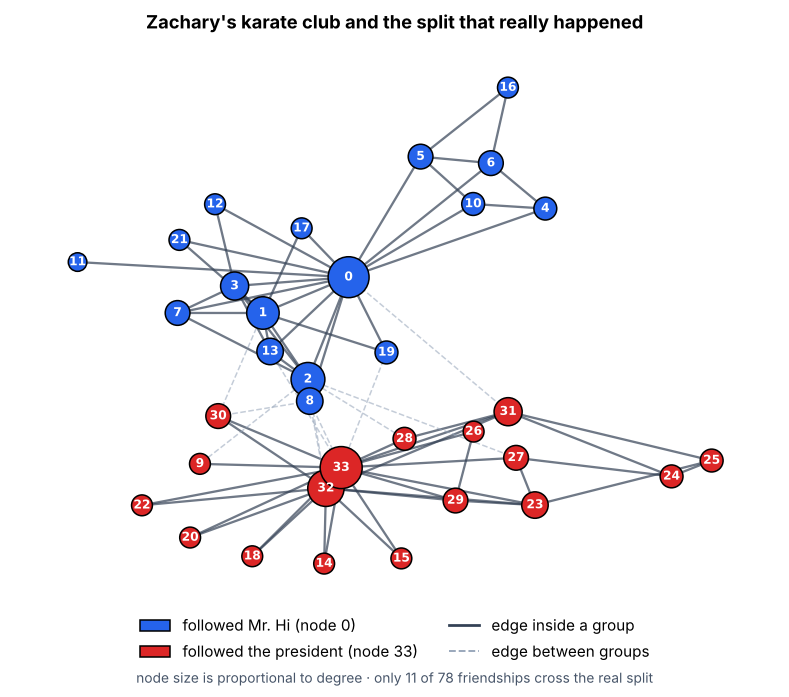

In [4]:
cut_truth = sum(truth[u] != truth[v] for u, v in G.edges())

fig, ax = plt.subplots(figsize=(9, 6.8))
draw_partition(ax, truth, title="Zachary's karate club and the split that really happened", node_size=110 + 38 * k)
ax.legend(handles=[Patch(facecolor=PALETTE[0], edgecolor="black", label="followed Mr. Hi (node 0)"),
                   Patch(facecolor=PALETTE[1], edgecolor="black", label="followed the president (node 33)")] + edge_legend,
          loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False)
ax.text(0.5, -0.12, f"node size is proportional to degree · only {cut_truth} of {m} friendships cross the real split",
        transform=ax.transAxes, ha="center", fontsize=9, color="#475569")
finish(fig, "01_real_split")

Only 11 of the 78 friendships cross the real split, so the two factions are clearly separated. That is what a good community-detection method should be able to pick up from the edges alone.

## 2. Modularity in brief

**Why not just cut the fewest edges?** The smallest cut often isolates one lonely vertex. Node 11 has a single friend, so cutting it off removes just one edge, but one member is not a community. We need a score that asks whether a group has *more* internal edges than chance would give.

**Null model.** Keep every node's degree $k_i$ but forget who is friends with whom: cut every edge in the middle to get $2m$ "stubs" and join the stubs at random. A stub of node $i$ lands on a stub of node $j$ with probability about $k_j/2m$, so the expected number of edges between $i$ and $j$ is

$$\mathbb{E}[A_{ij}] = k_i \cdot \frac{k_j}{2m} = \frac{k_i k_j}{2m}.$$

**Modularity matrix.** Real edges minus expected edges:

$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}, \qquad B = A - \frac{k k^\top}{2m}.$$

$B$ is real and symmetric, so its eigenvalues are real and it has an orthonormal set of eigenvectors. Every row of $B$ sums to zero, $B\mathbf{1} = 0$, so $0$ is always an eigenvalue of the full matrix.

**Modularity of a two-way split.** Write a split as a vector $s \in \{+1,-1\}^n$. Then

$$Q = \frac{1}{4m}\, s^\top B\, s .$$

$Q$ goes up when pairs with $B_{ij}>0$ are kept together and pairs with $B_{ij}<0$ are kept apart. Putting everybody in one group gives $Q = 0$, because $\mathbf{1}^\top B \mathbf{1} = 0$. For any number of communities we use the equivalent form $Q = \frac{1}{2m}\sum_{i,j\ \text{in the same community}} B_{ij}$, which is the same as $\sum_c \big[\,L_c/m - (d_c/2m)^2\,\big]$ with $L_c$ the edges inside community $c$ and $d_c$ the sum of its degrees.

**Spectral relaxation.** Trying all $2^n$ vectors is impossible ($2^{34} \approx 1.7\times 10^{10}$ for this club). So we drop the requirement $s_i=\pm1$ and only ask for $\|s\|_2 = 1$. By the Rayleigh–Ritz theorem,

$$\max_{\|s\|_2 = 1} s^\top B s = \lambda_1,$$

reached at the leading eigenvector $u_1$. Its entries are a soft assignment: strongly positive means "group 1", strongly negative means "group 2", close to zero means "not sure". We round back to a real split with the signs, $s_i = +1$ if $(u_1)_i > 0$ and $-1$ otherwise.

**Recursive bisection.** For a group $C$ take the block $B^{(C)}$: the rows and columns of $B$ that belong to $C$ (the degrees and $m$ stay those of the whole graph). The handout gives the gain from splitting $C$ with a vector $s$ as $\Delta Q = \frac{1}{4m}s^\top B^{(C)} s$, and by Rayleigh–Ritz this is at most $\frac{1}{4m}\lambda_1^{(C)}\,|C|$. So if $\lambda_1^{(C)} \le 0$ no split of $C$ can raise the modularity and $C$ is final. Otherwise we split $C$ by the signs of $u_1^{(C)}$ and repeat on both halves.

The method follows Newman (2006), *Modularity and community structure in networks* (see the references at the end).

## 3. Building the modularity matrix

Three quick checks on $B$ before we use it: it should be symmetric, its rows should sum to zero (so $0$ is an eigenvalue), and its largest eigenvalue should be positive, otherwise the club could not be split at all.

In [5]:
B = A - np.outer(k, k) / (2 * m)

eigvals = np.linalg.eigvalsh(B)
print("B is symmetric:          ", np.allclose(B, B.T))
print("largest |row sum| of B:  ", f"{np.abs(B.sum(axis=1)).max():.1e}", " (B @ 1 = 0)")
print("eigenvalue closest to 0: ", f"{np.abs(eigvals).min():.1e}")
print("largest eigenvalue:      ", f"{eigvals[-1]:.4f}")

B is symmetric:           True
largest |row sum| of B:   8.9e-16  (B @ 1 = 0)
eigenvalue closest to 0:  1.8e-18
largest eigenvalue:       4.9771


Two small helpers carry the whole method.

- `modularity` scores any partition.
- `spectral_split` takes a group of nodes, cuts out its block of $B$, finds the leading eigenpair with `np.linalg.eigh` (the block is symmetric) and returns the two halves given by the signs of the eigenvector.

An eigenvector comes with an arbitrary overall sign, so we flip it to make the smallest node id positive. That only decides which half is called "positive" (and so which colour it gets). The partition itself is not affected.

In [6]:
def modularity(labels, B, m):
    """Q of any partition: (1/2m) times the sum of B_ij over pairs in the same community."""
    labels = np.asarray(labels)
    same = labels[:, None] == labels[None, :]
    q = B[same].sum() / (2 * m)
    return 0.0 if abs(q) < 1e-12 else q          # avoids printing -0.0000 for the trivial partition

def spectral_split(nodes, B):
    """Split a group with the leading eigenvector of its block B^(C).
    Returns lambda_1, the eigenvector, and the positive / non-positive halves."""
    nodes = np.asarray(nodes)
    block = B[np.ix_(nodes, nodes)]
    vals, vecs = np.linalg.eigh(block)
    lam, u = vals[-1], vecs[:, -1]
    if u[0] < 0:          # eigenvectors have an arbitrary sign, so the smallest node id is always made positive
        u = -u
    return lam, u, nodes[u > 0], nodes[u <= 0]

**Test on a tiny graph first.** Two triangles joined by one bridge edge. Done by hand, $m = 7$, the split into the two triangles has $Q = 2\,(3/7 - (7/14)^2) = 0.357$, and the leading eigenvalue of $B$ is $\sqrt{3}$. The code should reproduce all of that.

In [7]:
toy = nx.Graph([(0, 1), (0, 2), (1, 2), (2, 3), (3, 4), (3, 5), (4, 5)])
A_t = nx.to_numpy_array(toy, nodelist=range(6))
k_t, m_t = A_t.sum(axis=1), toy.number_of_edges()
B_t = A_t - np.outer(k_t, k_t) / (2 * m_t)

lam_t, u_t, left, right = spectral_split(range(6), B_t)
print(f"lambda_1 = {lam_t:.3f}   (sqrt(3) = {np.sqrt(3):.3f})")
print("u_1      =", np.round(u_t, 2))
print("split    =", left.tolist(), "|", right.tolist())
print(f"Q        = {modularity([0, 0, 0, 1, 1, 1], B_t, m_t):.3f}   (hand calculation: 0.357)")

lambda_1 = 1.732   (sqrt(3) = 1.732)
u_1      = [ 0.44  0.44  0.33 -0.33 -0.44 -0.44]
split    = [0, 1, 2] | [3, 4, 5]
Q        = 0.357   (hand calculation: 0.357)


## 4. One spectral split

We apply the method once to the whole club: leading eigenvector of $B$, split by sign, then compare with the real factions.

In [8]:
lam1, u1, group_a, group_b = spectral_split(range(n), B)

first_split = np.where(np.isin(np.arange(n), group_a), 0, 1)
s = np.where(first_split == 0, 1, -1)

wrong = np.flatnonzero(first_split != truth)
cut_first = sum(first_split[u] != first_split[v] for u, v in G.edges())

print(f"leading eigenvalue  lambda_1 = {lam1:.4f}")
print(f"group sizes: {len(group_a)} and {len(group_b)}")
print(f"Q = s'Bs / 4m = {s @ B @ s / (4 * m):.4f}   (same value from the helper: {modularity(first_split, B, m):.4f})")
print(f"edges between the two groups: {cut_first} of {m}")
print(f"matches the real split for {n - len(wrong)} of {n} members, misplaced: {wrong.tolist()}")
print(f"entry of u_1 for the misplaced node: {u1[wrong[0]]:+.3f}")

leading eigenvalue  lambda_1 = 4.9771
group sizes: 16 and 18
Q = s'Bs / 4m = 0.3715   (same value from the helper: 0.3715)
edges between the two groups: 10 of 78
matches the real split for 33 of 34 members, misplaced: [8]
entry of u_1 for the misplaced node: -0.054


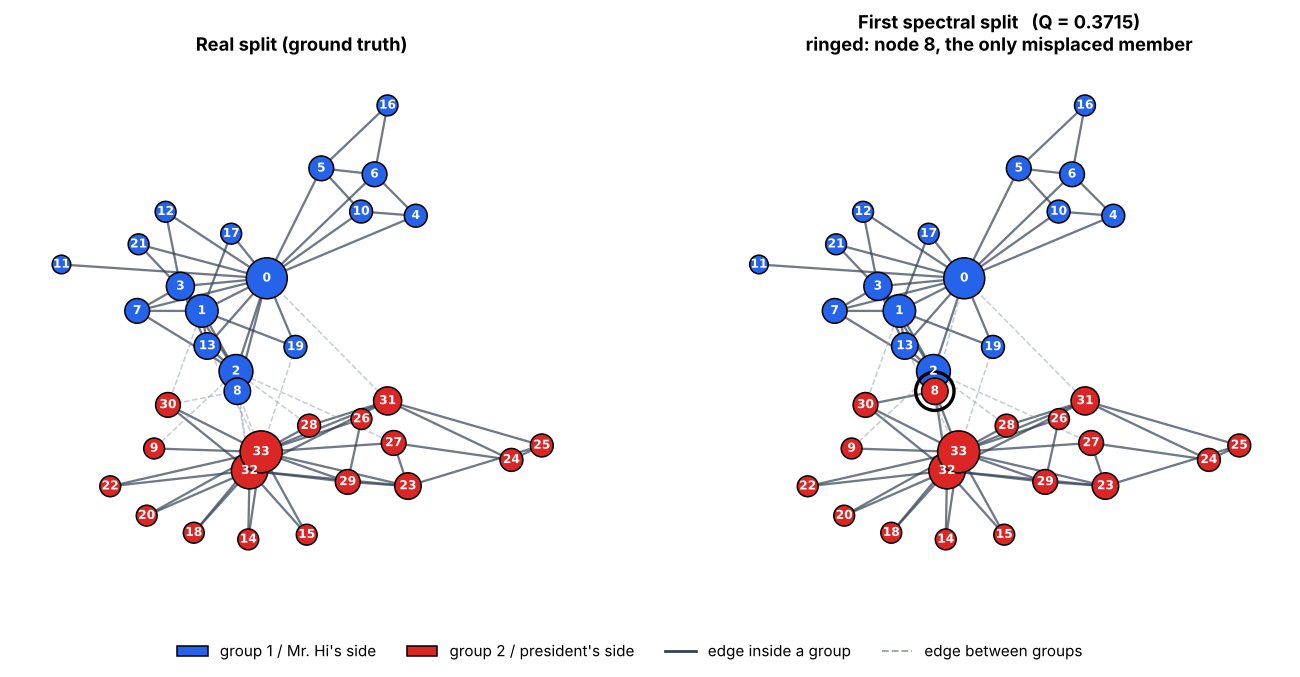

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
draw_partition(axes[0], truth, title="Real split (ground truth)", node_size=110 + 38 * k)
draw_partition(axes[1], first_split, node_size=110 + 38 * k, ring=wrong,
               title=f"First spectral split   (Q = {modularity(first_split, B, m):.4f})\nringed: node 8, the only misplaced member")
fig.legend(handles=[Patch(facecolor=PALETTE[0], edgecolor="black", label="group 1 / Mr. Hi's side"),
                    Patch(facecolor=PALETTE[1], edgecolor="black", label="group 2 / president's side")] + edge_legend,
           loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
finish(fig, "02_first_split_vs_truth")

Group 1 (16 nodes) is Mr. Hi's side and group 2 (18 nodes) is the president's side. Only 10 edges run between the groups, one fewer than the 11 that cross the real split. Node 8 is the only member placed on the wrong side.

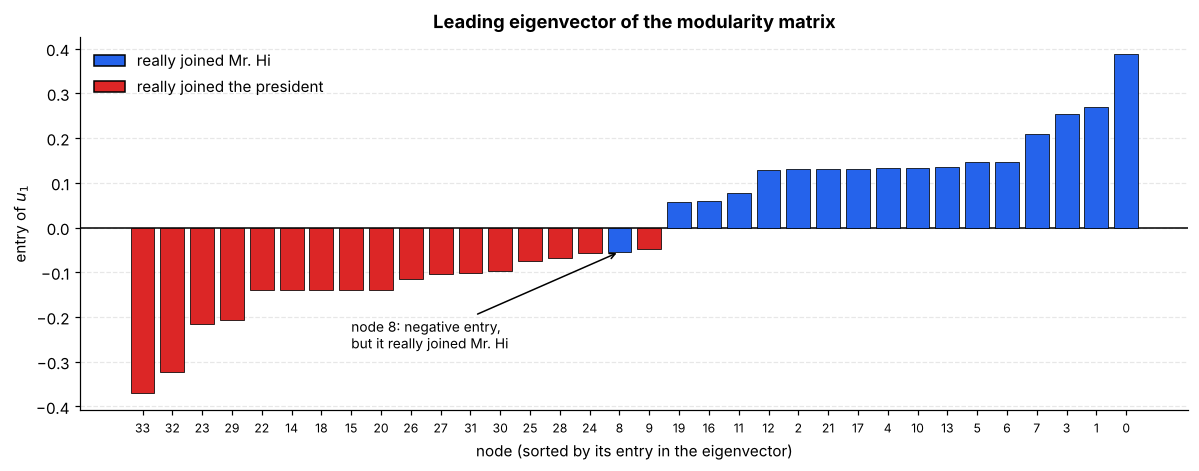

In [10]:
order = np.argsort(u1)
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.bar(range(n), u1[order], color=[PALETTE[truth[i]] for i in order], edgecolor="black", linewidth=0.5, zorder=3)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(n))
ax.set_xticklabels(order, fontsize=8)
ax.grid(axis="x", visible=False)

i8 = list(order).index(8)
ax.annotate("node 8: negative entry,\nbut it really joined Mr. Hi", xy=(i8, u1[8]), xytext=(i8 - 9, -0.27),
            fontsize=9, arrowprops=dict(arrowstyle="->"))
ax.legend(handles=[Patch(facecolor=PALETTE[0], edgecolor="black", label="really joined Mr. Hi"),
                   Patch(facecolor=PALETTE[1], edgecolor="black", label="really joined the president")],
          loc="upper left", frameon=False)
ax.set_xlabel("node (sorted by its entry in the eigenvector)")
ax.set_ylabel("entry of $u_1$")
ax.set_title("Leading eigenvector of the modularity matrix")
finish(fig, "03_leading_eigenvector")

The eigenvector tells us more than the signs. The two leaders sit at the two ends (node 33 at the far left, node 0 at the far right), and node 8, the single mistake, has an entry of $-0.054$, almost zero. So the method itself flags node 8 as a borderline member who is barely attached to either side.

## 5. Recursive bisection

Now we keep splitting. Each community waits in a queue. When it is its turn we

1. take its block $B^{(C)}$ and compute the leading eigenpair,
2. stop if $\lambda_1^{(C)} \le 0$ (the handout's rule), or if the eigenvector has the same sign everywhere (then there is nothing to divide),
3. otherwise split by sign: the positive half keeps the community id and the other half gets a new one, and both halves go back into the queue.

After every split we store the partition, so each stage can be plotted and analysed later. $Q$ is always computed on the whole partition.

In [11]:
LAM_TOL = 1e-8

labels = np.zeros(n, dtype=int)     # community id of every node
history = [labels.copy()]           # partition before the first split, then after every split
splits = []                         # one record per split
stopped = {}                        # why each final community was left alone
queue = [0]

while queue:
    cid = queue.pop(0)
    members = np.flatnonzero(labels == cid)
    lam, u, c_pos, c_neg = spectral_split(members, B)

    if lam <= LAM_TOL or len(c_pos) == 0 or len(c_neg) == 0:
        stopped[cid] = (lam, "lambda_1 <= 0" if lam <= LAM_TOL else "all entries of u_1 have the same sign")
        continue

    block = B[np.ix_(members, members)]
    s_loc = np.where(np.isin(members, c_pos), 1, -1)
    Q_before = modularity(labels, B, m)

    new_id = labels.max() + 1
    labels[c_neg] = new_id
    history.append(labels.copy())
    Q_after = modularity(labels, B, m)

    splits.append({
        "step": len(splits) + 1, "parent": cid, "members": members.tolist(),
        "pos": c_pos.tolist(), "neg": c_neg.tolist(), "lam": lam,
        "n_comm": labels.max() + 1, "Q": Q_after,
        "dQ_actual": Q_after - Q_before, "dQ_handout": s_loc @ block @ s_loc / (4 * m),
    })
    queue += [cid, new_id]

    print(f"Split {len(splits)}: community {cid} ({len(members)} nodes) -> {len(c_pos)} + {len(c_neg)}"
          f"   lambda_1 = {lam:.4f}   communities = {labels.max() + 1}   Q = {Q_after:.4f}")

final_labels = labels.copy()
n_comm = final_labels.max() + 1
Q_final = modularity(final_labels, B, m)

print(f"\nFinished: {n_comm} communities, Q = {Q_final:.4f}")
for c in range(n_comm):
    size_c = np.sum(final_labels == c)
    print(f"  community {c} ({size_c:>2} node{'s' if size_c > 1 else ' '}): {np.flatnonzero(final_labels == c).tolist()}")

Split 1: community 0 (34 nodes) -> 16 + 18   lambda_1 = 4.9771   communities = 2   Q = 0.3715
Split 2: community 0 (16 nodes) -> 10 + 6   lambda_1 = 2.9441   communities = 3   Q = 0.3898
Split 3: community 1 (18 nodes) -> 13 + 5   lambda_1 = 2.5041   communities = 4   Q = 0.4081
Split 4: community 2 (6 nodes) -> 5 + 1   lambda_1 = 2.1480   communities = 5   Q = 0.4094

Finished: 5 communities, Q = 0.4094
  community 0 (10 nodes): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  community 1 (13 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  community 2 ( 5 nodes): [4, 5, 6, 10, 16]
  community 3 ( 5 nodes): [24, 25, 27, 28, 31]
  community 4 ( 1 node ): [11]


In [12]:
split_table = pd.DataFrame([{
    "split": sp["step"],
    "group divided": f"community {sp['parent']} ({len(sp['members'])} nodes)",
    "lambda_1": sp["lam"],
    "new sizes": f"{len(sp['pos'])} + {len(sp['neg'])}",
    "communities": sp["n_comm"],
    "Q after split": sp["Q"],
    "gain in Q": sp["dQ_actual"],
    "gain by 1/4m s'B(C)s": sp["dQ_handout"],
} for sp in splits]).set_index("split")

stop_table = pd.DataFrame([{
    "community": c, "size": int(np.sum(final_labels == c)),
    "lambda_1 of its block": stopped[c][0], "left alone because": stopped[c][1],
} for c in sorted(stopped)]).set_index("community")

display(split_table.round(4))
display(stop_table.round(4))

,group divided,lambda_1,new sizes,communities,Q after split,gain in Q,gain by 1/4m s'B(C)s
split,,,,,,,
1,community 0 (34 nodes),4.9771,16 + 18,2,0.3715,0.3715,0.3715
2,community 0 (16 nodes),2.9441,10 + 6,3,0.3898,0.0183,0.1112
3,community 1 (18 nodes),2.5041,13 + 5,4,0.4081,0.0183,0.1112
4,community 2 (6 nodes),2.1480,5 + 1,5,0.4094,0.0013,0.0338


,size,lambda_1 of its block,left alone because
community,,,
0,10,2.5712,all entries of u_1 have the same sign
1,13,2.3563,all entries of u_1 have the same sign
2,5,2.1470,all entries of u_1 have the same sign
3,5,1.8759,all entries of u_1 have the same sign
4,1,-0.0064,lambda_1 <= 0


**Reading the tables.**

- The split order matches the story from the plots later on: the whole club first, then Mr. Hi's side, then the president's side, then the small group of six.
- Four of the five final communities were *not* stopped by $\lambda_1 \le 0$. Their leading eigenvalue is still positive, but the eigenvector has one sign everywhere, so the sign rule cannot divide them. Only the single node 11 stops by the $\lambda_1 \le 0$ rule. This is why the code checks for a trivial split as well.
- The last column is the gain predicted by the handout's identity $\frac{1}{4m}s^\top B^{(C)}s$ with the plain block. It equals the real gain for the first split, but for later splits it overshoots (for example $0.111$ instead of $0.018$ for split 2). The reason is that the community already counted as one piece before the split, and the plain block does not take that into account. Newman's generalised modularity matrix fixes this by subtracting each row sum of the block from its diagonal. We keep the handout's stopping rule as asked and report the real $Q$ of the whole partition throughout.

## 6. Visualising the communities

All plots use the same spring layout, so a node never moves between panels. Colours follow the community ids: a community that is split keeps its colour for one half and the other half gets a new colour. Solid edges are inside a community and dashed grey edges run between communities.

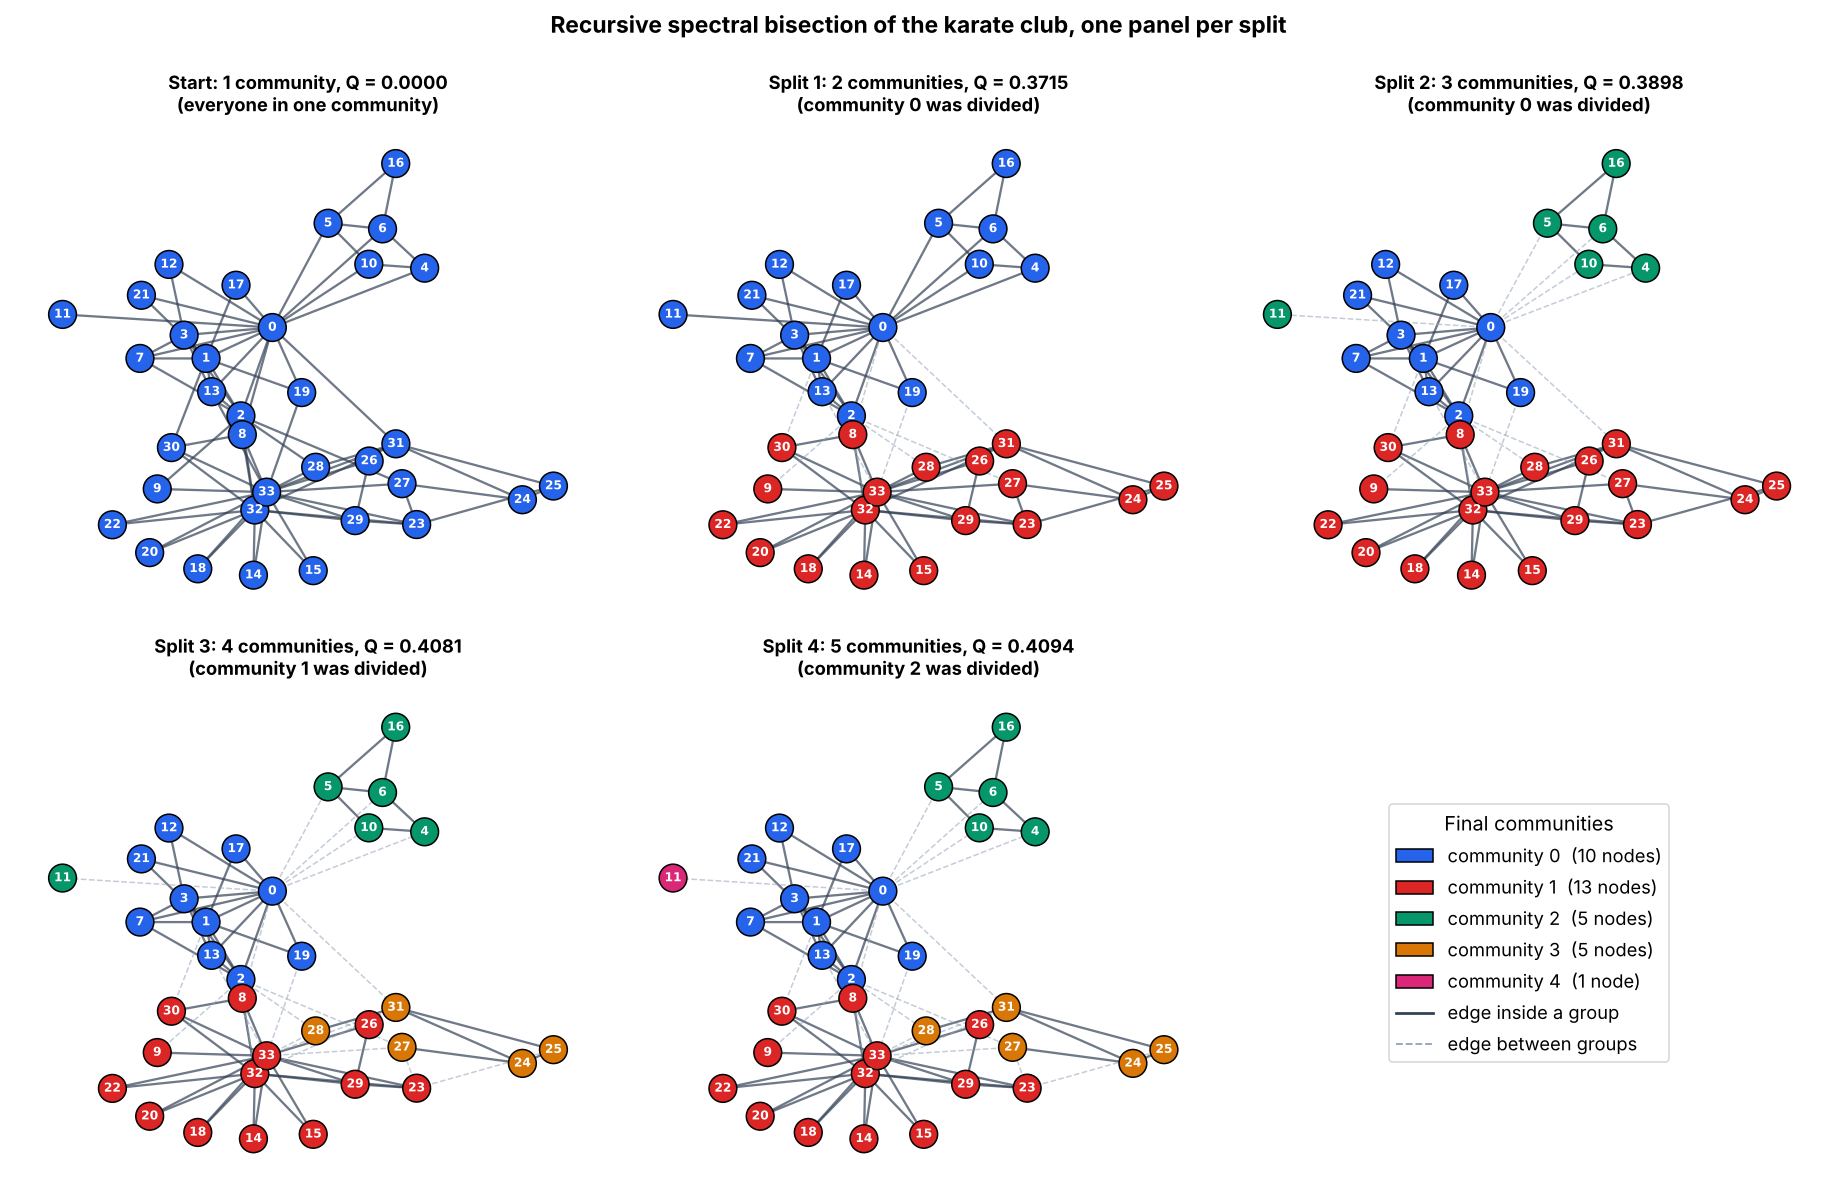

In [13]:
stage_names = ["Start"] + [f"Split {i}" for i in range(1, len(history))]
n_stage = len(history)
ncols = 3
nrows = int(np.ceil((n_stage + 1) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5.6 * ncols, 5.4 * nrows))
axes = axes.ravel()
for t in range(n_stage):
    lab = history[t]
    sub = "everyone in one community" if t == 0 else f"community {splits[t - 1]['parent']} was divided"
    draw_partition(axes[t], lab, title=f"{stage_names[t]}: {lab.max() + 1} communit{'y' if t == 0 else 'ies'}, "
                                      f"Q = {modularity(lab, B, m):.4f}\n({sub})", node_size=330)

legend_ax = axes[n_stage]
legend_ax.axis("off")
comm_sizes = np.bincount(final_labels)
legend_ax.legend(handles=[Patch(facecolor=PALETTE[c], edgecolor="black", label=f"community {c}  ({comm_sizes[c]} node{'s' if comm_sizes[c] > 1 else ''})")
                          for c in range(n_comm)] + edge_legend,
                 loc="center", fontsize=12, frameon=True, title="Final communities", title_fontsize=13)
for ax in axes[n_stage + 1:]:
    ax.axis("off")

fig.suptitle("Recursive spectral bisection of the karate club, one panel per split", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout()
finish(fig, "04_splits_grid")

- **Split 1** recovers the two factions (blue and red).
- **Split 2** peels nodes 4, 5, 6, 10, 16 and 11 off Mr. Hi's side. They are connected to the rest of the club almost only through node 0.
- **Split 3** takes nodes 24, 25, 27, 28 and 31 away from the president's side.
- **Split 4** separates node 11 from its group: it has just one friend (node 0), who is in a different community, so it ends up alone.

The same final partition on one larger picture, with the node size showing the degree and a soft background around each community.

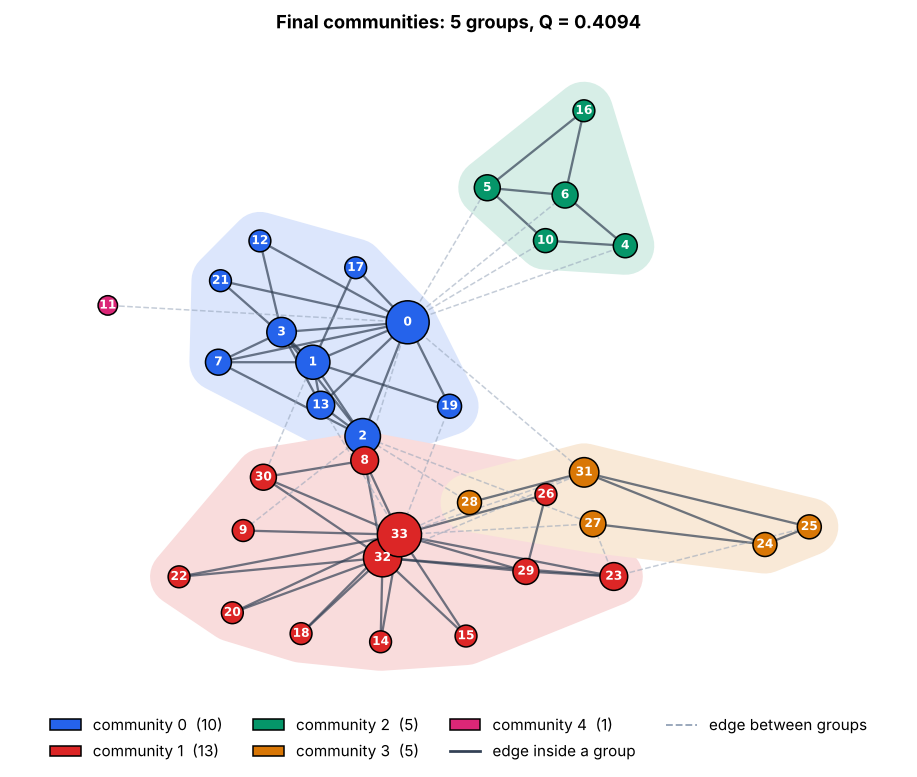

In [14]:
def shade_communities(ax, labels):
    """Soft background blob behind each community (rounded convex hull)."""
    for c in np.unique(labels):
        pts = np.array([pos[i] for i in np.flatnonzero(labels == c)])
        light = tuple(0.84 * 1 + 0.16 * np.array(to_rgb(PALETTE[c % len(PALETTE)])))
        if len(pts) >= 3:
            try:
                ax.add_patch(Polygon(pts[ConvexHull(pts).vertices], closed=True, facecolor=light, edgecolor=light,
                                     lw=38, joinstyle="round", zorder=0))
                continue
            except Exception:
                pass
        ax.plot(pts[:, 0], pts[:, 1], color=light, lw=38, solid_capstyle="round", zorder=0)

fig, ax = plt.subplots(figsize=(10.5, 8))
shade_communities(ax, final_labels)
draw_partition(ax, final_labels, title=f"Final communities: {n_comm} groups, Q = {Q_final:.4f}", node_size=120 + 42 * k)
ax.legend(handles=[Patch(facecolor=PALETTE[c], edgecolor="black", label=f"community {c}  ({comm_sizes[c]})") for c in range(n_comm)] + edge_legend,
          loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=4, frameon=False)
ax.margins(0.08)
finish(fig, "05_final_communities")

The split tree shows the order of the splits and the value of $\lambda_1$ that each one used. The leaves are the five final communities.

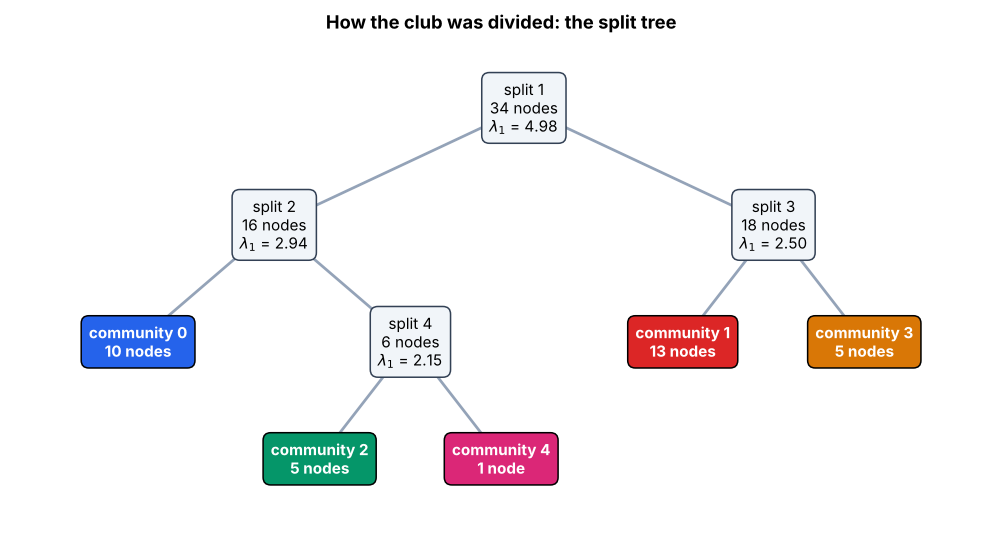

In [15]:
split_of = {tuple(sp["members"]): sp for sp in splits}
coords = {}
leaf_counter = [0]

def place(node, depth):
    sp = split_of.get(node)
    if sp is None:
        x = leaf_counter[0]
        leaf_counter[0] += 1
    else:
        x = np.mean([place(tuple(child), depth + 1) for child in (sp["pos"], sp["neg"])])
    coords[node] = (x, -depth)
    return x

place(tuple(range(n)), 0)

fig, ax = plt.subplots(figsize=(11.5, 5.8))
for node, (x, y) in coords.items():
    sp = split_of.get(node)
    if sp is None:
        continue
    for child in (sp["pos"], sp["neg"]):
        cx, cy = coords[tuple(child)]
        ax.plot([x, cx], [y, cy], color="#94A3B8", lw=1.8, zorder=1)

for node, (x, y) in coords.items():
    sp = split_of.get(node)
    if sp is None:
        c = final_labels[node[0]]
        text, face = f"community {c}\n{len(node)} node{'s' if len(node) > 1 else ''}", PALETTE[c]
        ax.text(x, y, text, ha="center", va="center", color="white", fontweight="bold", fontsize=10, zorder=3,
                bbox=dict(boxstyle="round,pad=0.5", facecolor=face, edgecolor="black"))
    else:
        text = f"split {sp['step']}\n{len(node)} nodes\n$\\lambda_1$ = {sp['lam']:.2f}"
        ax.text(x, y, text, ha="center", va="center", fontsize=10, zorder=3,
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#F1F5F9", edgecolor="#334155"))

ax.set_xlim(-0.7, leaf_counter[0] - 0.3)
ax.set_ylim(min(y for _, y in coords.values()) - 0.6, 0.6)
ax.axis("off")
ax.set_title("How the club was divided: the split tree")
finish(fig, "06_split_tree")

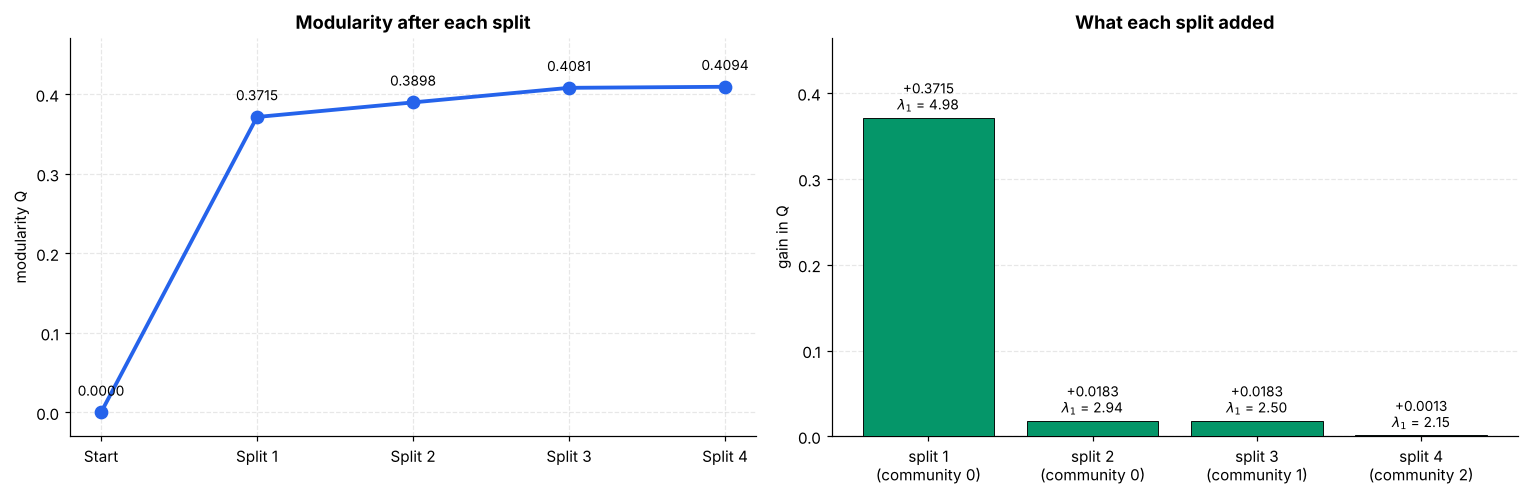

In [16]:
stage_Q = [modularity(lab, B, m) for lab in history]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

ax = axes[0]
ax.plot(range(n_stage), stage_Q, marker="o", ms=8, lw=2.5, color=PALETTE[0], zorder=3)
for t, q in enumerate(stage_Q):
    ax.annotate(f"{q:.4f}", (t, q), textcoords="offset points", xytext=(0, 11), ha="center", fontsize=9)
ax.set_xticks(range(n_stage))
ax.set_xticklabels(stage_names)
ax.set_ylim(-0.03, max(stage_Q) * 1.15)
ax.set_ylabel("modularity Q")
ax.set_title("Modularity after each split")

ax = axes[1]
gains = [sp["dQ_actual"] for sp in splits]
ax.bar(range(len(gains)), gains, color=PALETTE[2], edgecolor="black", linewidth=0.6, zorder=3)
for i, sp in enumerate(splits):
    ax.annotate(f"+{sp['dQ_actual']:.4f}\n$\\lambda_1$ = {sp['lam']:.2f}", (i, sp["dQ_actual"]), textcoords="offset points",
                xytext=(0, 5), ha="center", fontsize=9)
ax.set_xticks(range(len(gains)))
ax.set_xticklabels([f"split {sp['step']}\n(community {sp['parent']})" for sp in splits])
ax.set_ylim(0, max(gains) * 1.25)
ax.grid(axis="x", visible=False)
ax.set_ylabel("gain in Q")
ax.set_title("What each split added")
fig.tight_layout()
finish(fig, "07_modularity_progress")

Almost all of the modularity comes from the very first split, which gives $0.3715$ out of the final $0.4094$ (about 91%). The later splits each add a little ($+0.018$, $+0.018$, $+0.001$), and the gains shrink with every step.

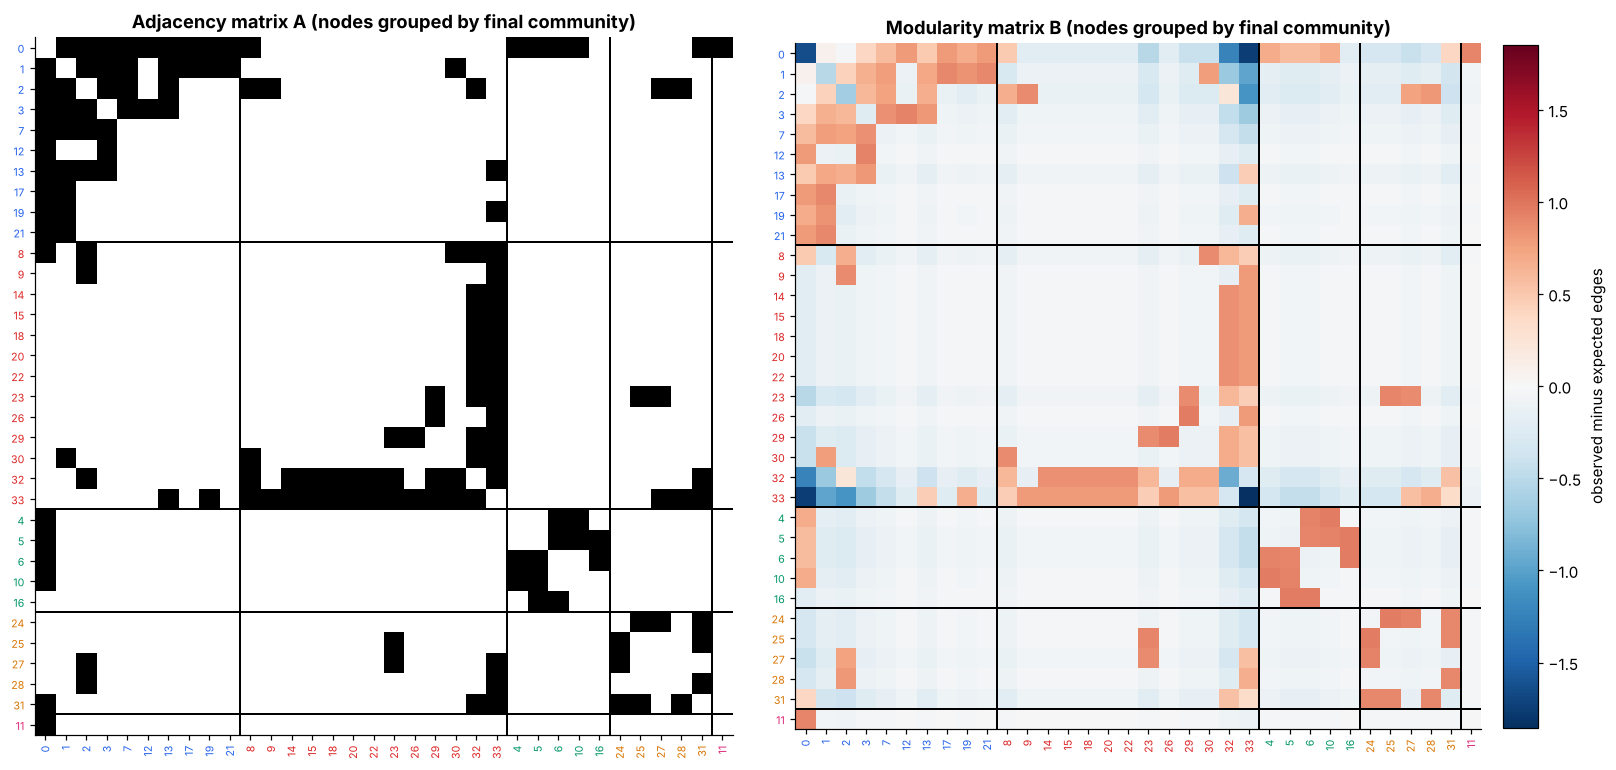

In [17]:
order = np.argsort(final_labels, kind="stable")
edges_at = np.cumsum(np.bincount(final_labels))[:-1] - 0.5
tick_colors = [PALETTE[final_labels[i] % len(PALETTE)] for i in order]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
panels = [(A[np.ix_(order, order)], "Adjacency matrix A", "Greys", (0, 1)),
          (B[np.ix_(order, order)], "Modularity matrix B", "RdBu_r", (-np.abs(B).max(), np.abs(B).max()))]
for ax, (mat, title, cmap, (lo, hi)) in zip(axes, panels):
    im = ax.imshow(mat, cmap=cmap, vmin=lo, vmax=hi)
    for e in edges_at:
        ax.axhline(e, color="black", lw=1.3)
        ax.axvline(e, color="black", lw=1.3)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(order, fontsize=7, rotation=90)
    ax.set_yticklabels(order, fontsize=7)
    for tl, col in zip(ax.get_xticklabels(), tick_colors):
        tl.set_color(col)
    for tl, col in zip(ax.get_yticklabels(), tick_colors):
        tl.set_color(col)
    ax.grid(False)
    ax.set_title(title + " (nodes grouped by final community)")
    if cmap == "RdBu_r":
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="observed minus expected edges")
fig.tight_layout()
finish(fig, "08_block_structure")

A last view of the result: the adjacency matrix and the modularity matrix with the nodes grouped by final community. The communities show up as dense blocks on the diagonal of $A$ and as warm (positive) blocks in $B$, meaning more edges than chance. The hubs 0, 32 and 33 have strongly negative entries towards the nodes they are not connected to, which is what the null model expects for a node with a high degree.

## 7. Node metrics after every split

For every node we compute the four measures from the handout with NetworkX.

| Metric | Formula | High value means |
|---|---|---|
| Degree centrality | $C_D(i) = \dfrac{k_i}{n-1}$ | a hub with many direct links |
| Betweenness centrality | $C_B(i) = \sum_{s\neq i\neq t} \dfrac{\sigma_{st}(i)}{\sigma_{st}}$ | a bridge on many shortest paths |
| Closeness centrality | $C_C(i) = \dfrac{n-1}{\sum_{j\neq i} d(i,j)}$ | can reach everybody in few steps |
| Clustering coefficient | $C(i) = \dfrac{2\,T(i)}{k_i(k_i-1)}$ | sits in a tight group of friends |

**Why the graph has to change.** The metrics only depend on the graph, so on the unchanged graph they would be identical after every split. After each split we therefore remove the edges that run *between* different communities and recompute. The values then describe how central a node is **inside its own community**.

Two NetworkX defaults to keep in mind: betweenness is normalised to lie between 0 and 1, and closeness is scaled by the fraction of the other nodes that can be reached, so it shrinks for nodes in small components.

In [18]:
METRICS = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def graph_inside_communities(labels):
    """Copy of the graph with every edge between two different communities removed."""
    H = G.copy()
    H.remove_edges_from([(u, v) for u, v in G.edges() if labels[u] != labels[v]])
    return H

def node_metrics(H):
    out = {}
    for name, fn in METRICS.items():
        values = fn(H)
        out[name] = np.array([values[i] for i in range(n)])
    return out

stage_graphs = [graph_inside_communities(lab) for lab in history]
per_stage = [node_metrics(H) for H in stage_graphs]
M = {name: np.vstack([ps[name] for ps in per_stage]) for name in METRICS}   # shape (stages, nodes)

rows = []
for t in range(n_stage):
    for i in range(n):
        rows.append({"stage": stage_names[t], "node": i, "community": int(final_labels[i]),
                     **{name: M[name][t, i] for name in METRICS}})
metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(OUT_DIR / "node_metrics_by_stage.csv", index=False)

stage_summary = pd.DataFrame({
    "edges kept": [H.number_of_edges() for H in stage_graphs],
    "edges removed": [m - H.number_of_edges() for H in stage_graphs],
    "components": [nx.number_connected_components(H) for H in stage_graphs],
    **{f"mean {name.lower()}": M[name].mean(axis=1) for name in METRICS},
}, index=stage_names)
display(stage_summary.round(3))

,edges kept,edges removed,components,mean degree centrality,mean betweenness centrality,mean closeness centrality,mean clustering coefficient
Start,78,0,1,0.139,0.044,0.426,0.571
Split 1,68,10,2,0.121,0.013,0.270,0.684
Split 2,63,15,4,0.112,0.009,0.216,0.640
Split 3,57,21,5,0.102,0.005,0.165,0.641
Split 4,57,21,5,0.102,0.005,0.165,0.641


After splits 1, 2 and 3 the graph has lost 10, 15 and 21 edges (78 → 57) and has fallen apart into five components. The last split removes no edge at all, since node 11 was already cut off from its group, so the means do not change between Split 3 and Split 4.

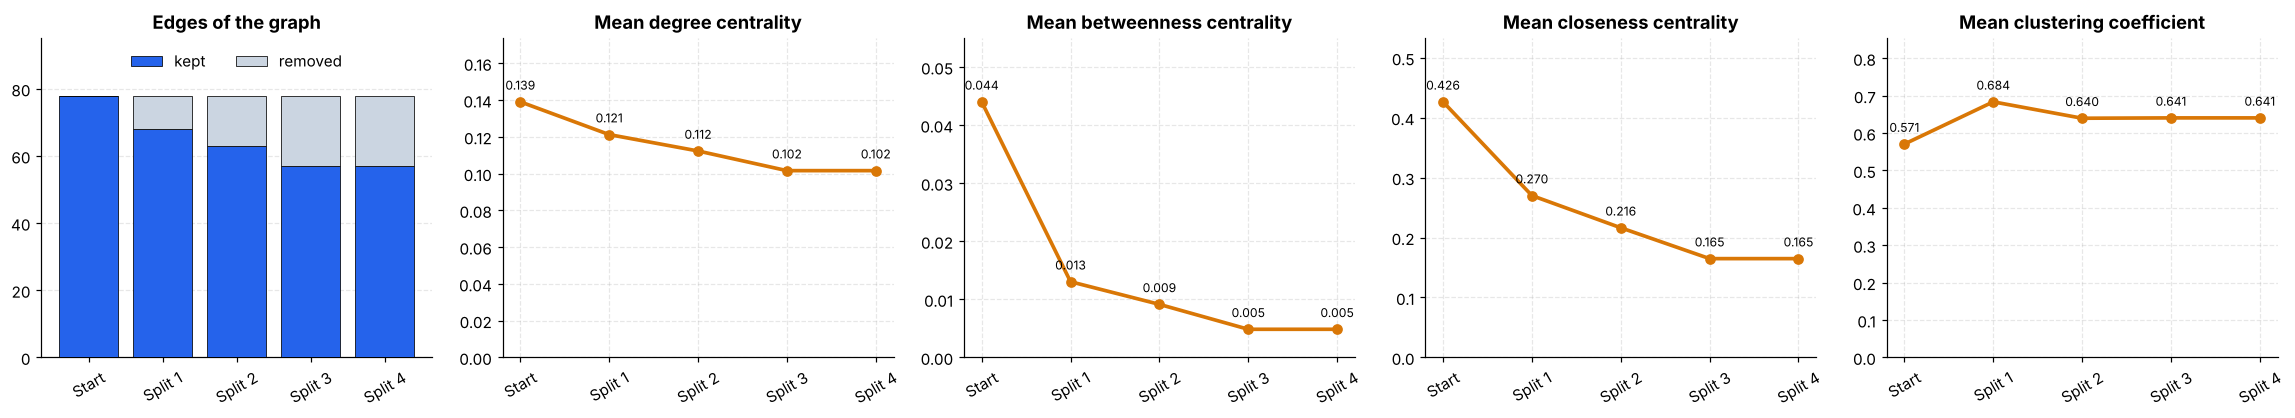

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(21, 3.9))

ax = axes[0]
ax.bar(stage_names, stage_summary["edges kept"], color=PALETTE[0], edgecolor="black", linewidth=0.5, label="kept", zorder=3)
ax.bar(stage_names, stage_summary["edges removed"], bottom=stage_summary["edges kept"], color="#CBD5E1",
       edgecolor="black", linewidth=0.5, label="removed", zorder=3)
ax.set_title("Edges of the graph")
ax.set_ylim(0, m * 1.22)
ax.legend(frameon=False, loc="upper center", ncol=2)
ax.grid(axis="x", visible=False)

for ax, (name, vals) in zip(axes[1:], M.items()):
    mean = vals.mean(axis=1)
    ax.plot(stage_names, mean, marker="o", lw=2.4, color=PALETTE[3], zorder=3)
    for t, v in enumerate(mean):
        ax.annotate(f"{v:.3f}", (t, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    ax.set_ylim(0, mean.max() * 1.25)
    ax.set_title(f"Mean {name.lower()}")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
finish(fig, "09_graph_and_mean_metrics")

On average betweenness collapses (−89%), closeness drops a lot (−61%), degree falls moderately (−27%), and clustering goes **up** (+12%).

**Evolution of every metric for every node.** Thin lines are the 30 other nodes coloured by their final community. The four highlighted nodes are the two leaders (0 and 33), node 2 (a bridge between the factions) and node 8 (the borderline member).

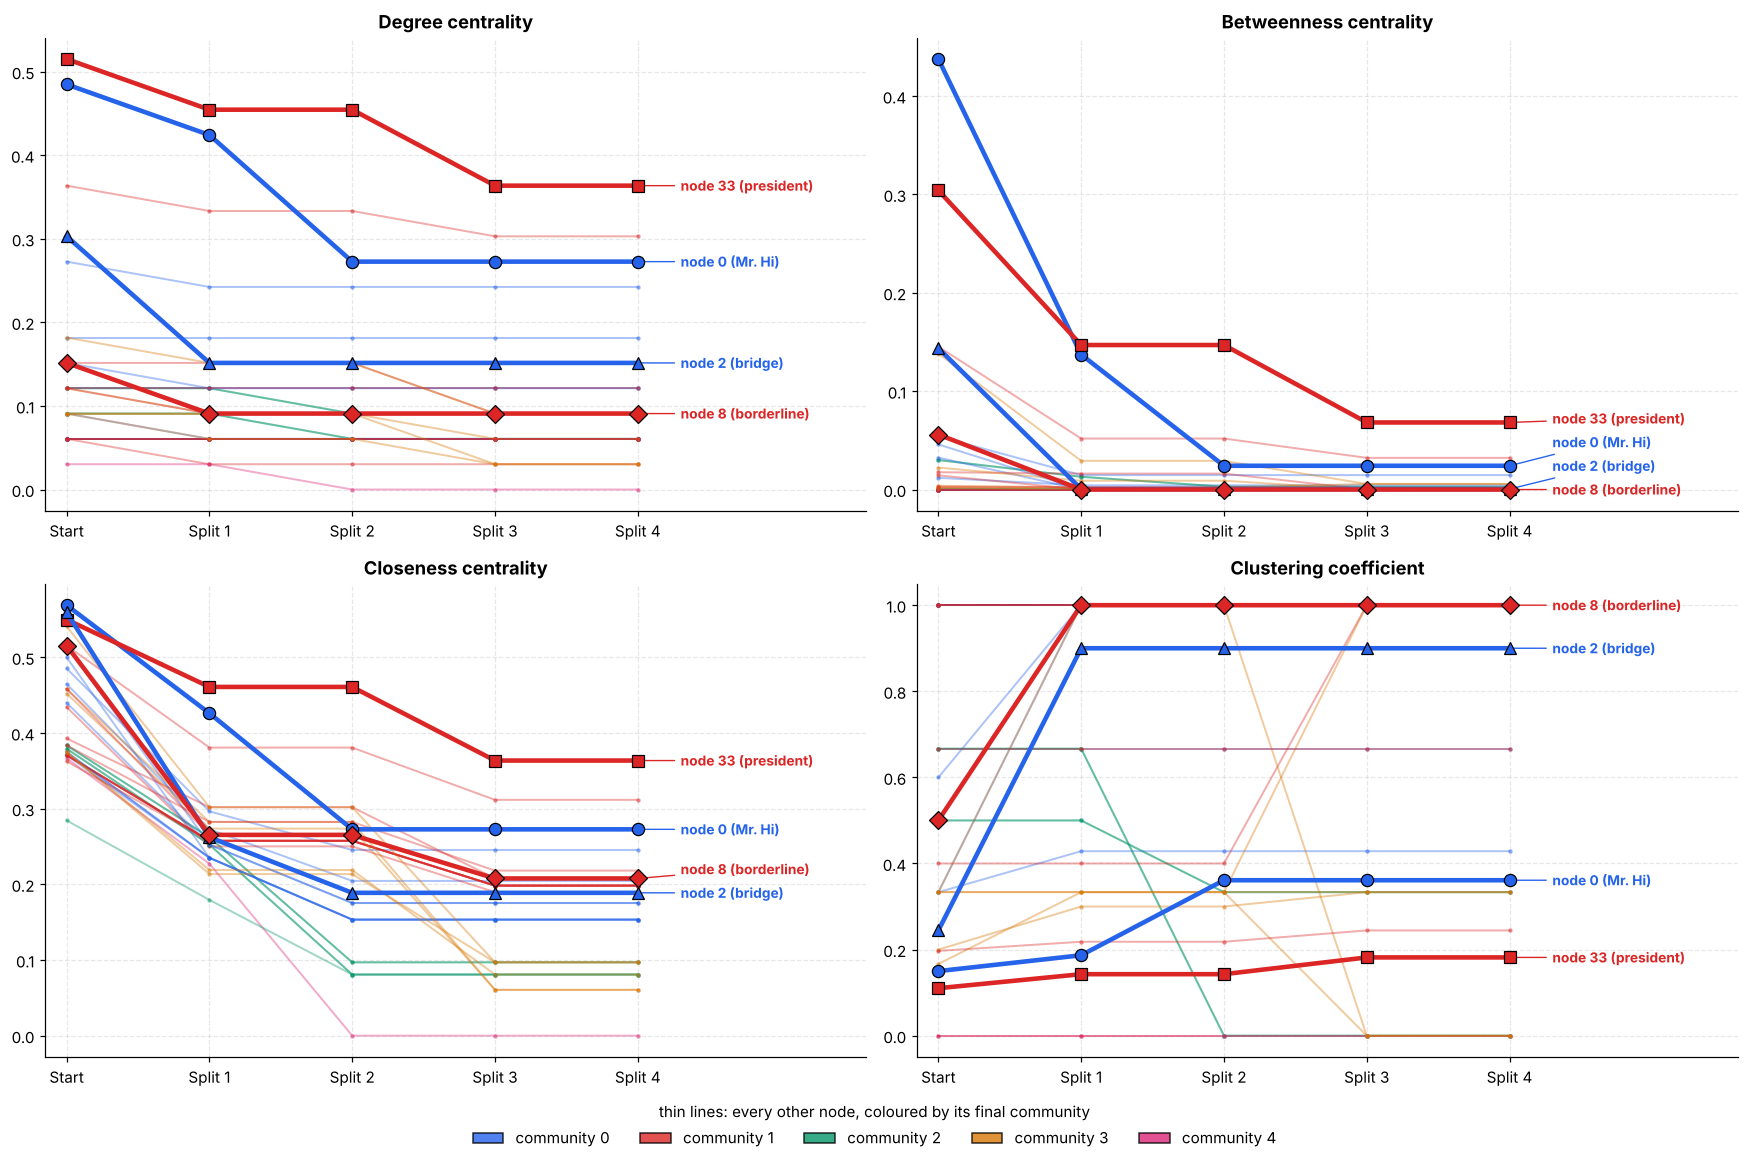

In [20]:
HIGHLIGHT = {
    0:  ("node 0 (Mr. Hi)", "o"),
    33: ("node 33 (president)", "s"),
    2:  ("node 2 (bridge)", "^"),
    8:  ("node 8 (borderline)", "D"),
}

def spread(values, gap):
    """Nudge label heights apart so that neighbouring labels do not overlap."""
    order = np.argsort(values)
    adj = np.asarray(values, dtype=float)[order]
    for i in range(1, len(adj)):
        adj[i] = max(adj[i], adj[i - 1] + gap)
    out = np.empty_like(adj)
    out[order] = adj
    return out

fig, axes = plt.subplots(2, 2, figsize=(16, 10.5))
x = np.arange(n_stage)
for ax, (name, vals) in zip(axes.ravel(), M.items()):
    for i in range(n):
        if i not in HIGHLIGHT:
            ax.plot(x, vals[:, i], color=PALETTE[final_labels[i]], alpha=0.38, lw=1.3, marker=".", ms=4, zorder=2)

    ends = [vals[-1, i] for i in HIGHLIGHT]
    ypos = spread(ends, 0.055 * (vals.max() - vals.min() + 1e-9))
    for (i, (label, marker)), y_end, y_lab in zip(HIGHLIGHT.items(), ends, ypos):
        col = PALETTE[final_labels[i]]
        ax.plot(x, vals[:, i], color=col, lw=3, marker=marker, ms=8, mec="black", mew=0.8, zorder=5)
        ax.annotate(label, xy=(x[-1], y_end), xytext=(x[-1] + 0.3, y_lab), va="center", fontsize=9, color=col, fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color=col, lw=0.9))
    ax.set_xticks(x)
    ax.set_xticklabels(stage_names)
    ax.set_xlim(-0.15, n_stage - 1 + 1.6)
    ax.set_title(name)

fig.legend(handles=[Patch(facecolor=PALETTE[c], edgecolor="black", alpha=0.8, label=f"community {c}") for c in range(n_comm)],
           loc="lower center", ncol=n_comm, frameon=False, bbox_to_anchor=(0.5, -0.01), title="thin lines: every other node, coloured by its final community")
fig.tight_layout(rect=(0, 0.04, 1, 1))
finish(fig, "10_metric_evolution")

The same data as a heatmap: one row per node (grouped by final community, label colour = community), one column per stage. Dark means a high value.

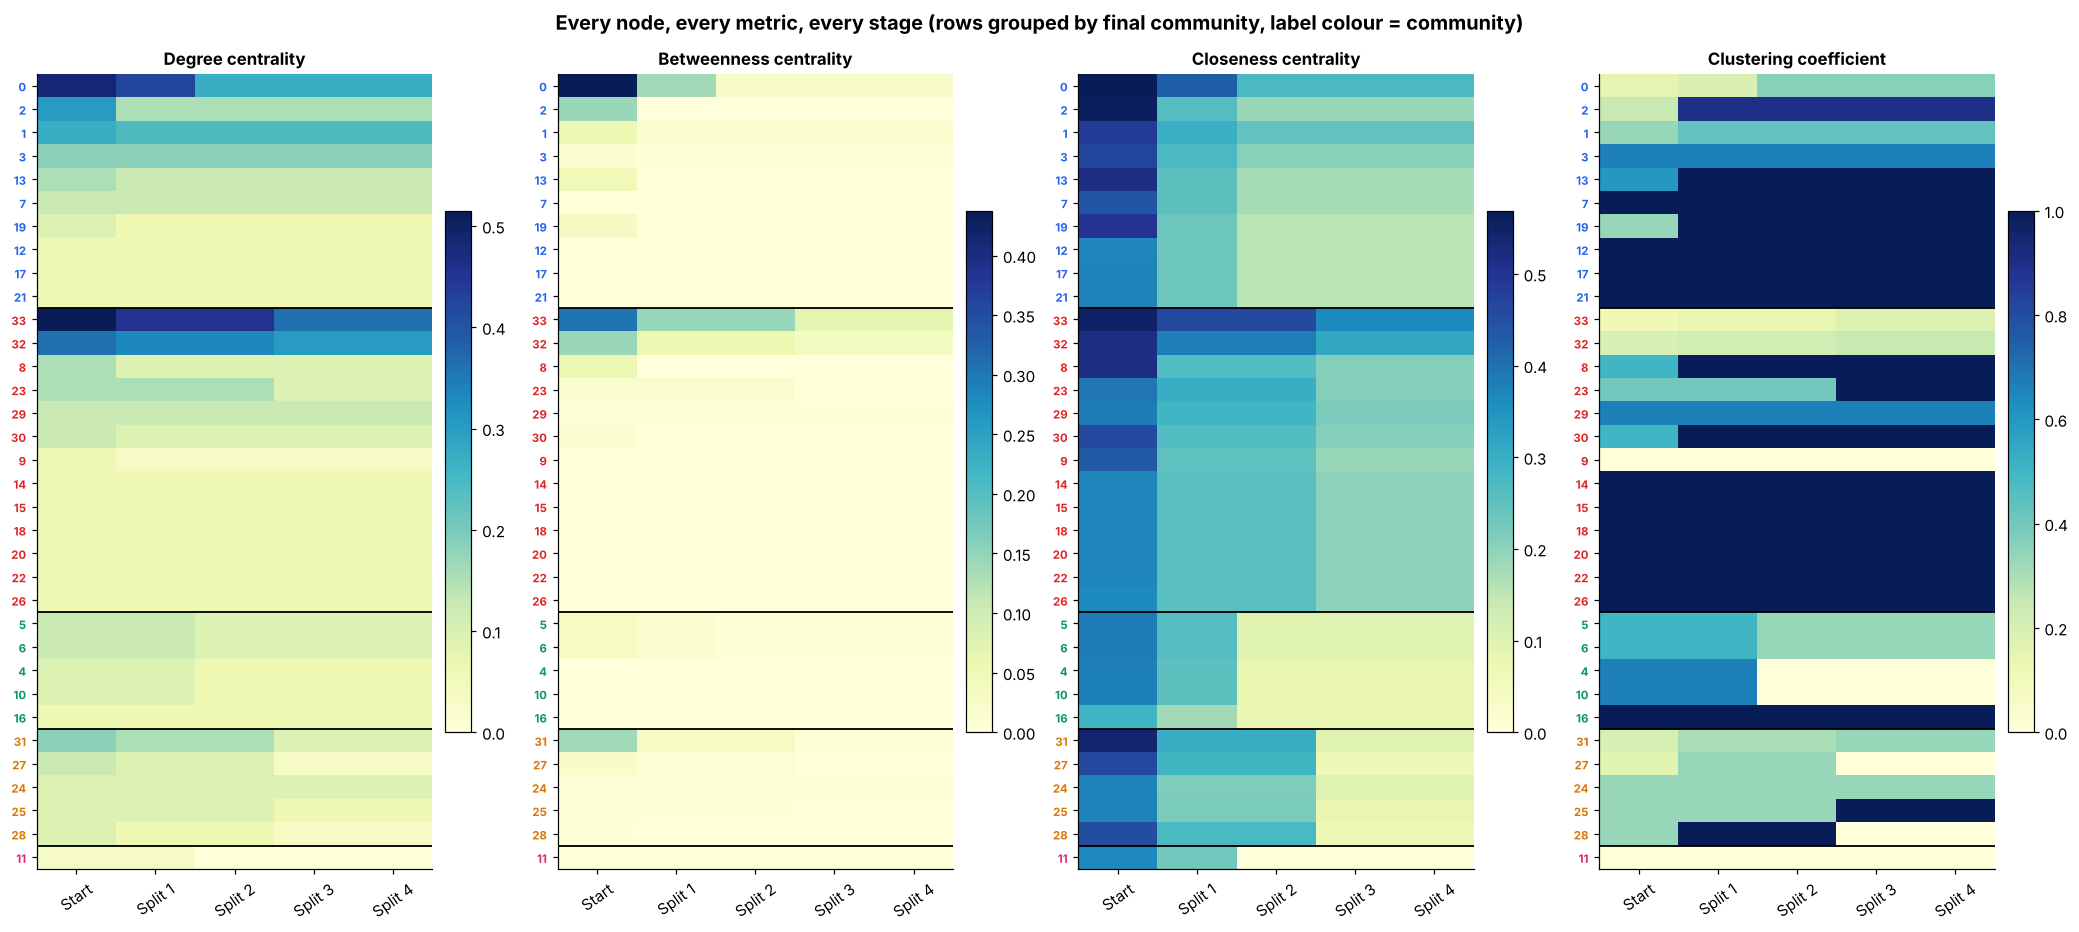

In [21]:
node_order = np.lexsort((-k, final_labels))      # group by community, highest degree first
group_edges = np.cumsum(np.bincount(final_labels))[:-1] - 0.5

fig, axes = plt.subplots(1, 4, figsize=(19, 8.6))
for ax, (name, vals) in zip(axes, M.items()):
    im = ax.imshow(vals[:, node_order].T, aspect="auto", cmap="YlGnBu", vmin=0)
    for e in group_edges:
        ax.axhline(e, color="black", lw=1.2)
    ax.set_xticks(range(n_stage))
    ax.set_xticklabels(stage_names, rotation=35)
    ax.set_yticks(range(n))
    ax.set_yticklabels(node_order, fontsize=7.5)
    for tl, i in zip(ax.get_yticklabels(), node_order):
        tl.set_color(PALETTE[final_labels[i]])
        tl.set_fontweight("bold")
    ax.grid(False)
    ax.set_title(name, fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.06, pad=0.03)
fig.suptitle("Every node, every metric, every stage (rows grouped by final community, label colour = community)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
finish(fig, "11_metric_heatmaps")

**Which nodes stay central?** For each stage we take the five most central nodes (ties at the cut-off all count) and count in how many of the five stages each node made the list. The clustering coefficient is left out, because a high clustering value does not mean a node is central.

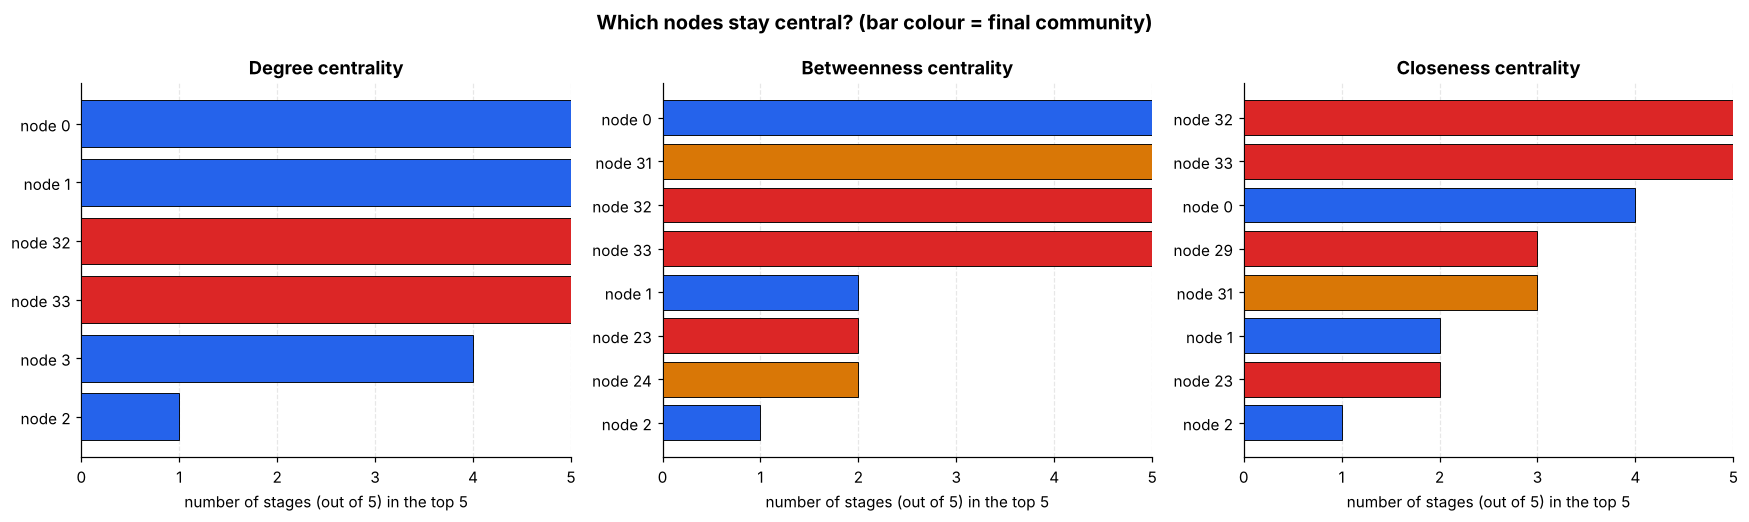

In [22]:
TOP_K = 5
central = ["Degree centrality", "Betweenness centrality", "Closeness centrality"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, name in zip(axes, central):
    appearances = np.zeros(n, dtype=int)
    for t in range(n_stage):
        v = M[name][t]
        cutoff = np.sort(v)[-TOP_K]
        appearances[v >= cutoff - 1e-12] += 1          # ties at the cutoff all count

    top = np.argsort(-appearances, kind="stable")[:8]
    top = top[appearances[top] > 0][::-1]
    ax.barh([f"node {i}" for i in top], appearances[top], color=[PALETTE[final_labels[i]] for i in top],
            edgecolor="black", linewidth=0.6, zorder=3)
    ax.set_xlim(0, n_stage)
    ax.set_xticks(range(n_stage + 1))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"number of stages (out of {n_stage}) in the top {TOP_K}")
    ax.set_title(name)
fig.suptitle("Which nodes stay central? (bar colour = final community)", fontweight="bold", fontsize=13)
fig.tight_layout()
finish(fig, "12_stable_central_nodes")

Values for the leaders and a few bridge nodes, from the original graph to the graph after the last split:

In [23]:
key_nodes = [33, 0, 32, 1, 2, 31, 8]
roles = {33: "president", 0: "instructor", 2: "bridge", 31: "bridge", 8: "bridge"}

key_table = pd.DataFrame([{
    "node": f"{i} ({roles[i]})" if i in roles else str(i),
    **{name: f"{M[name][0, i]:.2f} → {M[name][-1, i]:.2f}" for name in METRICS},
} for i in key_nodes]).set_index("node")

print("value on the original graph → value after the last split")
display(key_table)

value on the original graph → value after the last split


,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
node,,,,
33 (president),0.52 → 0.36,0.30 → 0.07,0.55 → 0.36,0.11 → 0.18
0 (instructor),0.48 → 0.27,0.44 → 0.02,0.57 → 0.27,0.15 → 0.36
32,0.36 → 0.30,0.15 → 0.03,0.52 → 0.31,0.20 → 0.24
1,0.27 → 0.24,0.05 → 0.01,0.49 → 0.25,0.33 → 0.43
2 (bridge),0.30 → 0.15,0.14 → 0.00,0.56 → 0.19,0.24 → 0.90
31 (bridge),0.18 → 0.09,0.14 → 0.01,0.54 → 0.10,0.20 → 0.33
8 (bridge),0.15 → 0.09,0.06 → 0.00,0.52 → 0.21,0.50 → 1.00


## 8. Discussion

### Which nodes stay central across the splits?

- **The leaders and node 32.** Nodes 33, 0, 32 and 1 are among the five highest-degree nodes at every stage, and node 33 has the highest degree centrality at every single stage (0.52 → 0.36). Their friendships are mostly with their own side, so cutting between the communities removes few of their edges. Nodes 33 and 32 also stay in the top five for closeness at every stage.
- **Betweenness keeps the same names but loses its scale.** Nodes 0, 33, 32 and 31 stay in the top five at every stage, but the values shrink a lot. Node 0 starts as the strongest broker (0.44) and falls to 0.14 after split 1 and 0.02 at the end. From split 1 on, node 33 has the highest betweenness of all (0.30 at the start, 0.07 at the end).
- **Node 31 is a special case.** Its betweenness falls from 0.14 to 0.01, yet it stays in the top five. It is still the best connected node of its small community (24, 25, 27, 28, 31), so it stays a local broker even though it has lost its role between the factions.

### How does community structure shape the metrics?

1. **Betweenness drops the most (mean 0.044 → 0.005).** Shortest paths between communities no longer exist after the cut. Nodes 4, 5, 6, 10, 16 and 11 reach the rest of the club only through node 0, which is why node 0 loses so much once they form their own community.
2. **Bridge nodes fall hardest.** Node 2 has 10 friends and 5 of them (8, 9, 27, 28, 32) are on the other side. After split 1 its degree centrality is halved (0.30 → 0.15) and its betweenness is 0. Nodes 8 and 31 also lose most of their betweenness. A node's importance in the original graph can come from sitting *between* groups, and that disappears as soon as the groups are separated.
3. **Closeness falls (mean 0.43 → 0.16).** Every node can now reach only its own community. Part of the fall comes from NetworkX scaling closeness by the share of reachable nodes: a member of a five-node community can reach only 4 of the 33 others, so its value is small whatever the distances inside are.
4. **Clustering mostly rises (mean 0.57 → 0.64).** The edges that are removed are the ones that lead to friends who are not friends with the rest of the node's neighbourhood, so what is left is tighter. Node 2 goes from 0.24 to 0.90 and node 8 from 0.50 to 1.00. It does not rise for everybody: nodes 4 and 10 drop from 0.67 to 0 because their triangles went through node 0, and node 11 is left with no edges and gets 0 for all four metrics.
5. **The metrics now describe a role inside a community.** After the splits, a high value means "central among my own group", not "central in the club". This is why node 33, a hub on the president's side, keeps a high degree but loses most of its betweenness.

### Caveats

The sign of the leading eigenvector is a relaxation of the real problem, so the split is an approximation (it is good here, with one error out of 34). The results also describe one small network with a known split. How much the metrics change depends on how the communities are cut, so we would not expect the exact numbers to carry over to other networks.

## 9. Conclusion

### Final check: communities against the real factions

How the five communities line up with the two real factions, and the key numbers of the run:

In [24]:
names = np.array(["Mr. Hi", "president"])
display(pd.crosstab(pd.Series(final_labels, name="final community"), pd.Series(names[truth], name="real faction")))

print(f"first split alone : Q = {stage_Q[1]:.4f}   ({n - len(wrong)}/{n} members on the correct side)")
print(f"final partition   : Q = {Q_final:.4f}   ({n_comm} communities after {len(splits)} splits)")

first split alone : Q = 0.3715   (33/34 members on the correct side)
final partition   : Q = 0.4094   (5 communities after 4 splits)


real faction,Mr. Hi,president
final community,,
0,10,0
1,1,12
2,5,0
3,0,5
4,1,0


- A single eigenvector of the modularity matrix, split by sign, recovers the real division of the karate club with 33 of 34 members right and $Q = 0.3715$. The one misplaced member (node 8) is exactly the one whose eigenvector entry is closest to zero.
- Applying the same step recursively gives five communities after four splits and $Q = 0.4094$. About 91% of that value comes from the first split.
- The final communities are: Mr. Hi's core (10 nodes), the president's core (13), the group around nodes 4, 5, 6, 10, 16 (5), the group around nodes 24, 25, 27, 28, 31 (5), and node 11 alone.
- Recomputing the node metrics inside the communities shows that bridge nodes lose most of their importance, betweenness and closeness fall sharply, clustering rises, and the leaders and node 32 stay central on their own side.

### References

1. M. E. J. Newman (2006). *Modularity and community structure in networks.* Proceedings of the National Academy of Sciences 103(23), 8577–8582.
2. W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research 33(4), 452–473.
3. A. A. Hagberg, D. A. Schult, P. J. Swart (2008). *Exploring network structure, dynamics, and function using NetworkX.* Proceedings of the 7th Python in Science Conference (SciPy 2008).

### USE OF AI
The starting code (recursive spectral bisection, modularity computation, metric tracking and some initial visualization) was written by me. I used Claude(Thanks you Dario!!!!! 🥰🥰🥰🥰) to restructure the code, fix the sign-orientation step, write the markdown explanations, and design additional visualizations.